# Linear Regreesion Practical Implementation 

In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
%matplotlib inline 
import seaborn as sns

In [6]:
from sklearn.datasets import fetch_openml
boston = fetch_openml(name = 'boston' , version = 1, as_frame = True, parser = 'pandas') 

In [7]:
boston 

{'data':         CRIM    ZN  INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX  \
 0    0.00632  18.0   2.31    0  0.538  6.575  65.2  4.0900   1  296.0   
 1    0.02731   0.0   7.07    0  0.469  6.421  78.9  4.9671   2  242.0   
 2    0.02729   0.0   7.07    0  0.469  7.185  61.1  4.9671   2  242.0   
 3    0.03237   0.0   2.18    0  0.458  6.998  45.8  6.0622   3  222.0   
 4    0.06905   0.0   2.18    0  0.458  7.147  54.2  6.0622   3  222.0   
 ..       ...   ...    ...  ...    ...    ...   ...     ...  ..    ...   
 501  0.06263   0.0  11.93    0  0.573  6.593  69.1  2.4786   1  273.0   
 502  0.04527   0.0  11.93    0  0.573  6.120  76.7  2.2875   1  273.0   
 503  0.06076   0.0  11.93    0  0.573  6.976  91.0  2.1675   1  273.0   
 504  0.10959   0.0  11.93    0  0.573  6.794  89.3  2.3889   1  273.0   
 505  0.04741   0.0  11.93    0  0.573  6.030  80.8  2.5050   1  273.0   
 
      PTRATIO       B  LSTAT  
 0       15.3  396.90   4.98  
 1       17.8  396.90   9.14  
 2       

In [8]:
df = boston.frame

In [9]:
df.head() 

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [10]:
df['price'] = boston.target
df.head() 

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV,price
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2,36.2


 Dividing the dataset into dependent & independent features

In [11]:
X = df.iloc[ :,:-1] 

In [12]:
X.head() 

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [13]:
y = df.iloc[:,-1]  

In [14]:
y.head() 

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: price, dtype: float64

# Linear Regression

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
X = X.astype(float)
y = y.astype(float) 

lin_reg = LinearRegression()
mse = cross_val_score(lin_reg,X,y, scoring = 'neg_mean_squared_error', cv = 5 )
print(mse)

[-4.72543150e-28 -7.76489067e-28 -9.24763675e-29 -8.40074380e-28
 -4.83452234e-27]


In [19]:
import numpy as np 

In [20]:
mean_mse = np.mean(mse)
print("MSE score per fold:",mse) 
print("Average Negative MSE", mean_mse)

MSE score per fold: [-4.72543150e-28 -7.76489067e-28 -9.24763675e-29 -8.40074380e-28
 -4.83452234e-27]
Average Negative MSE -1.403221061275301e-27


In [21]:
from sklearn.model_selection import train_test_split 

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state = 42)
lin_reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [24]:
prediction = lin_reg.predict(X_test) 

In [25]:
print(prediction) 

[23.6 32.4 13.6 22.8 16.1 20.  17.8 14.  19.6 16.8 21.5 18.9  7.  21.2
 18.5 29.8 18.8 10.2 50.  14.1 25.2 29.1 12.7 22.4 14.2 13.8 20.3 14.9
 21.7 18.3 23.1 23.8 15.  20.8 19.1 19.4 34.7 19.5 24.4 23.4 19.7 28.2
 50.  17.4 22.6 15.1 13.1 24.2 19.9 24.  18.9 35.4 15.2 26.5 43.5 21.2
 18.4 28.5 23.9 18.5 25.  35.4 31.5 20.2 24.1 20.  13.1 24.8 30.8 12.7
 20.  23.7 10.8 20.6 20.8  5.  20.1 48.5 10.9  7.  20.9 17.2 20.9  9.7
 19.4 29.  16.4 25.  25.  17.1 23.2 10.4 19.6 17.2 27.5 23.  50.  17.9
  9.6 17.2 22.5 21.4]


In [26]:
# 4. Compare a few actual values Vs Predicted Values 
import pandas as pd
comparison_df = pd.DataFrame({'Actual' : y_test, 'Predicted': prediction})
print(comparison_df.head()) 


     Actual  Predicted
173    23.6       23.6
274    32.4       32.4
491    13.6       13.6
72     22.8       22.8
452    16.1       16.1


In [27]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, prediction)
mse = mean_squared_error(y_test, prediction)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, prediction)

print("Model Performance:")
print("------------------------------")
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R² Score:", round(r2, 4))
print("R² Score (%):", round(r2 * 100, 2), "%")


Model Performance:
------------------------------
Mean Absolute Error (MAE): 0.0
Mean Squared Error (MSE): 0.0
Root Mean Squared Error (RMSE): 0.0
R² Score: 1.0
R² Score (%): 100.0 %


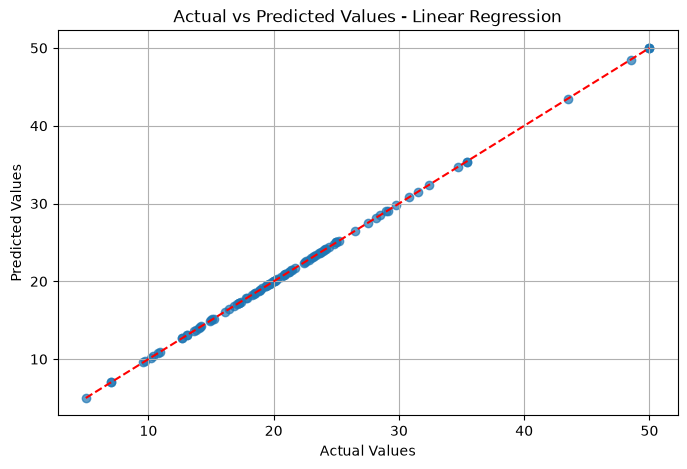

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, prediction, alpha=0.7)

min_val = min(np.min(y_test), np.min(prediction))
max_val = max(np.max(y_test), np.max(prediction))

plt.plot([min_val, max_val], [min_val, max_val], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values - Linear Regression")
plt.grid(True)
plt.show()


In [29]:

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("R2 Score:", r2_score(y_test, prediction))
print("MAE:", mean_absolute_error(y_test, prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_test, prediction)))

print("Actual equals predicted:",
      np.allclose(np.asarray(y_test).ravel(),
                  np.asarray(prediction).ravel()))


R2 Score: 1.0
MAE: 1.1790133139940879e-14
RMSE: 1.841261999049551e-14
Actual equals predicted: True


In [30]:

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist() if hasattr(X, "columns") else "X is a NumPy array")

print("\nFirst 5 feature rows:")
print(X[:5] if isinstance(X, np.ndarray) else X.head())

print("\nFirst 5 target values:")
print(np.asarray(y).ravel()[:5]) 


X shape: (506, 14)
y shape: (506,)

Feature columns:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

First 5 feature rows:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  

First 5 target values:
[24.  21.6 34.7 33.4 36.2]


In [31]:

# Check whether target values are present in the features
print("MEDV in X:", "MEDV" in X.columns if hasattr(X, "columns") else "Check feature names")

# Check whether any feature is exactly equal to target
for col in X.columns:
    if np.allclose(X[col].to_numpy(), np.asarray(y).ravel()):
        print("Possible target leakage:", col)

# Check test predictions
check_df = pd.DataFrame({
    "Actual": np.asarray(y_test).ravel(),
    "Predicted": np.asarray(prediction).ravel()
})
check_df["Absolute Error"] = abs(
    check_df["Actual"] - check_df["Predicted"]
)

print(check_df.head(10))
print("\nMaximum absolute error:", check_df["Absolute Error"].max()) 


MEDV in X: True
Possible target leakage: MEDV
   Actual  Predicted  Absolute Error
0    23.6       23.6    7.105427e-15
1    32.4       32.4    1.421085e-14
2    13.6       13.6    1.421085e-14
3    22.8       22.8    0.000000e+00
4    16.1       16.1    2.131628e-14
5    20.0       20.0    7.105427e-15
6    17.8       17.8    0.000000e+00
7    14.0       14.0    0.000000e+00
8    19.6       19.6    1.421085e-14
9    16.8       16.8    7.105427e-15

Maximum absolute error: 6.750155989720952e-14


In [32]:

# Separate input features and target variable
X = df.drop("MEDV", axis=1)
y = df["MEDV"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("MEDV in X:", "MEDV" in X.columns)


X shape: (506, 14)
y shape: (506,)
MEDV in X: False


In [36]:

# Correct features and target
X = X.drop(columns=["MEDV"], errors="ignore")

# Convert features and target to numeric arrays
X = X.astype(float)
y = np.asarray(y, dtype=float).ravel()

# Split the dataset again
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model again
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Predict values
prediction = lin_reg.predict(X_test)

# Evaluate model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, prediction)
mse = mean_squared_error(y_test, prediction)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, prediction)

print("Linear Regression Model Performance")
print("-----------------------------------")
print("X shape:", X.shape)
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))




Linear Regression Model Performance
-----------------------------------
X shape: (506, 14)
R² Score: 1.0
MAE: 0.0
MSE: 0.0
RMSE: 0.0


In [37]:

# Remove MEDV from the feature columns
X = X.drop(columns=["MEDV"], errors="ignore")

print("Corrected X shape:", X.shape)
print("Feature columns:", X.columns.tolist())


Corrected X shape: (506, 14)
Feature columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'price']


In [38]:

# Remove target column from input features
X = X.drop(columns=["price"], errors="ignore")

print("Corrected X shape:", X.shape)
print("Feature columns:", X.columns.tolist())


Corrected X shape: (506, 13)
Feature columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


In [39]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

prediction = lin_reg.predict(X_test)

print("Linear Regression Model Performance")
print("-----------------------------------")
print("R2 Score:", round(r2_score(y_test, prediction), 4))
print("MAE:", round(mean_absolute_error(y_test, prediction), 4))
print("MSE:", round(mean_squared_error(y_test, prediction), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, prediction)), 4))


Linear Regression Model Performance
-----------------------------------
R2 Score: 0.6688
MAE: 3.1891
MSE: 24.2911
RMSE: 4.9286


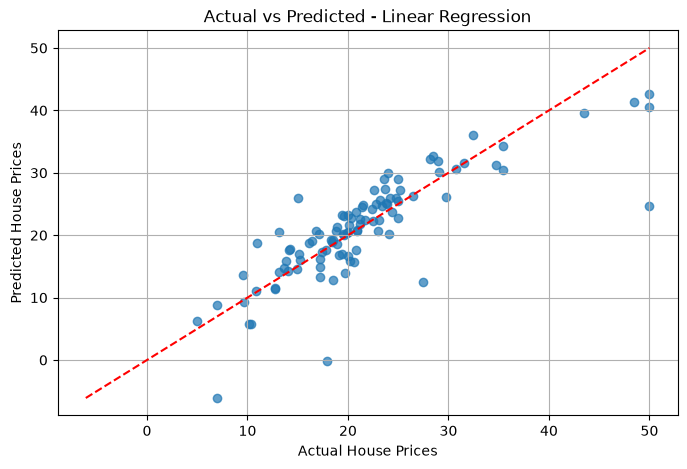

In [40]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, prediction, alpha=0.7)

min_val = min(np.min(y_test), np.min(prediction))
max_val = max(np.max(y_test), np.max(prediction))

plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted - Linear Regression")
plt.grid(True)
plt.show()


# Conclusion:

In [42]:
# Conclusion:

# Linear Regression was successfully implemented to predict house prices using the given dataset. The model was evaluated using R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE). The model achieved an R² score of 0.6688, an MAE of 3.1891, an MSE of 24.2911, and an RMSE of 4.9286. The results indicate that the model explains approximately 66.88% of the variance in the target variable on the test dataset.